# CoMETs Tutorial: Population Latent Encoder + Unit Identity Encoder

Two-stage pipeline for neural time-series:
1. **Stage 1** — Latent population encoder: learns `Z [T, D]`
2. **Stage 2** — Unit identity encoder: learns `E [N, d_u]`

Notebook structure:
1. **Train Latent** — PCA baseline + CoMETs (3 α_cross)
2. **Eval Latent** — window-average ridge decode, MAE + R² table
3. **Trajectory Plots** — predicted vs true position
4. **Grid-Search Unit** — latent × unit-loss grid, split-half pairs
5. **Eval Unit** — 3 metrics per embedding, ranked table

## 0. Setup

In [1]:
# ══════════════════════════════════════════════════════════════
# CONFIGURE — edit here, all cells below pick up the changes
# ══════════════════════════════════════════════════════════════

EPOCHS   = 100   # Stage 1 + Stage 2; split-half uses EPOCHS // 2
PROJ_DIM = 8     # latent embedding dimension  (Stage 1 output Z)
D_U      = 16     # unit embedding dimension    (Stage 2 output E)

# Stage 1 — latent conditions  (label, LatentTrainingConfig kwargs)
#   alpha_cross: cross-modal (spike↔LFP) loss weight
#   beta:        spike weight in the within-modality loss  (1-beta = LFP weight)
LATENT_CONDITIONS = [
    ("CEBRA",     dict(alpha_cross=0.0, beta=0.5)),   # no cross-modal
    ("Spike-dom", dict(alpha_cross=0.1, beta=0.95)),   # cross-modal; spike-dominant
    ("Balanced",  dict(alpha_cross=0.1, beta=0.6)),   # cross-modal; balanced spike+LFP
]
LAT_ORDER = ["PCA"] + [name for name, _ in LATENT_CONDITIONS]

# Stage 2 — unit loss grid; edit freely  (label, UnitTrainingConfig kwargs)
UNIT_CFGS = [
    ("Coact-only", dict(lambda_coact=0.8, lambda_ctx=0.2)),
    ("Balanced",   dict(lambda_coact=0.5, lambda_ctx=0.5)),
    ("Ctx-only",   dict(lambda_coact=0.2, lambda_ctx=0.8)),
]

print(f"EPOCHS={EPOCHS}  PROJ_DIM={PROJ_DIM}  D_U={D_U}")
print(f"Latent conditions: {LAT_ORDER}")
print(f"Unit configs:      {[n for n,_ in UNIT_CFGS]}")
print(f"Grid: {len(LAT_ORDER)} × {len(UNIT_CFGS)} = {len(LAT_ORDER)*len(UNIT_CFGS)} embeddings")

EPOCHS=100  PROJ_DIM=8  D_U=16
Latent conditions: ['PCA', 'CEBRA', 'Spike-dom', 'Balanced']
Unit configs:      ['Coact-only', 'Balanced', 'Ctx-only']
Grid: 4 × 3 = 12 embeddings


In [2]:
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys

from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from scipy.ndimage import gaussian_filter1d

import torch
import torch.nn.functional as F

for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (p / "comets" / "__init__.py").exists():
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        break

for mod in list(sys.modules):
    if mod == "comets" or mod.startswith("comets."):
        del sys.modules[mod]

import comets
from comets import (
    ModalityConfig, SamplingConfig,
    LatentTrainingConfig, UnitTrainingConfig,
    CEBRASKipEncoder, SkippedConvEncoderConfig,
    LinearHead,
    train_latent, train_unit,
)
from comets.unit_eval import ratemap_correlation, si_gradient_correlation, split_half_stability

print("Imports OK")
print(f"  comets loaded from: {comets.__file__}")

Imports OK
  comets loaded from: /mnt/d/comets/code/comets_test1/comets/__init__.py


In [3]:
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("WARNING: CUDA not available — training will be ~10x slower on CPU.")

CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation
GPU memory: 17.2 GB


## 1. Load Data

In [4]:
session = "ec013.156"

cwd = Path.cwd().resolve()
repo_root = next(
    (p for p in [cwd, *cwd.parents] if (p / "data" / "crcns_mouse").exists()), None
)
load_path = repo_root / "data" / "crcns_mouse" / session / f"{session}_lfp_spike.pkl"

with open(load_path, "rb") as f:
    data = pickle.load(f)

print(f"Loaded: {load_path}")
print(f"Available keys: {sorted(data.keys())}")

lfp_theta_full   = np.asarray(data["lfp_theta_50hz"]).astype(np.float32)
spike_count_full = np.asarray(data["spike_bin"])
spike_rate_full  = np.asarray(data["spike_rate"])
position_full    = np.asarray(data["position_50hz"])
fs_common        = data["fs_common"]
bin_size_ms      = data["bin_size_ms_spike"]
track_mode       = data.get("track_mode", "linear")

if position_full.ndim == 2:
    position_full = position_full[:, 0]

print(f"Track mode: {track_mode}")
print(f"LFP (theta 50Hz): {lfp_theta_full.shape}   fs={fs_common} Hz")
print(f"Spikes (counts):  {spike_count_full.shape}   bin={bin_size_ms} ms")
print(f"Position:         {position_full.shape}")

Loaded: /mnt/d/comets/data/crcns_mouse/ec013.156/ec013.156_lfp_spike.pkl
Available keys: ['bin_size_ms_spike', 'fs_common', 'fs_lfp', 'head_direction', 'lfp_raw', 'lfp_theta', 'lfp_theta_50hz', 'position_50hz', 'position_raw', 'session', 'session_dir', 'speed', 'spike_bin', 'spike_bin_smoothed', 'spike_rate', 'spike_raw', 'theta_band', 'track_mode']
Track mode: linear
LFP (theta 50Hz): (51179, 64)   fs=50 Hz
Spikes (counts):  (51179, 83)   bin=20 ms
Position:         (51179,)


## 2. Preprocessing + Region of Interest

In [5]:
window_start = 10001
window_end   = 30000     # 15 000 bins = 300 s at 50 Hz

spike_count_roi = spike_count_full[window_start:window_end].astype(np.float32)
spike_rate_roi  = spike_rate_full[window_start:window_end].astype(np.float32)
lfp_roi         = lfp_theta_full[window_start:window_end].astype(np.float32)
position_roi    = position_full[window_start:window_end]

rmin = spike_rate_roi.min(axis=0, keepdims=True)
rmax = spike_rate_roi.max(axis=0, keepdims=True)
spike_norm_roi = (spike_rate_roi - rmin) / (rmax - rmin + 1e-9)   # [T, N]

T, N = spike_count_roi.shape
_, C = lfp_roi.shape

print(f"ROI: [{window_start}, {window_end}]  →  T={T} bins  ({T/fs_common:.0f} s)")
print(f"N = {N} neurons,  C = {C} LFP channels")

color_code = np.linspace(0, 1, T)

ROI: [10001, 30000]  →  T=19999 bins  (400 s)
N = 83 neurons,  C = 64 LFP channels


## 3. Utility Functions

In [6]:
def reduce_to_3d(Z):
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    return Z[:, 0], Z[:, 1], Z[:, 2]


def window_ridge_decode(Z_spikes, position, Z_lfp=None, win_size=10, train_frac=0.7, alpha=1.0):
    """
    Average non-overlapping win_size-bin windows, optionally concat Z_lfp,
    fit Ridge, predict position.  Returns (mae, r2, y_pred_test, n_train_windows).
    """
    Z   = np.asarray(Z_spikes, dtype=np.float64)
    pos = np.asarray(position, dtype=np.float64)
    T_  = min(len(Z), len(pos))
    nw  = T_ // win_size
    Z_w = Z[:nw * win_size].reshape(nw, win_size, -1).mean(axis=1)
    y_w = pos[:nw * win_size].reshape(nw, win_size).mean(axis=1)
    if Z_lfp is not None:
        Zl   = np.asarray(Z_lfp, dtype=np.float64)
        Zl_w = Zl[:nw * win_size].reshape(nw, win_size, -1).mean(axis=1)
        Z_w  = np.concatenate([Z_w, Zl_w], axis=1)
    ntr   = int(train_frac * nw)
    reg   = Ridge(alpha=alpha).fit(Z_w[:ntr], y_w[:ntr])
    y_hat = reg.predict(Z_w[ntr:])
    mae   = float(np.mean(np.abs(y_w[ntr:] - y_hat)))
    r2    = float(r2_score(y_w[ntr:], y_hat))
    return mae, r2, y_hat, ntr


def compute_ratemaps(spike_counts, position, n_bins=40, sigma=2.0):
    """Occupancy-normalized rate maps [N, n_bins] and bin centres [n_bins]."""
    edges    = np.linspace(position.min(), position.max(), n_bins + 1)
    centers  = 0.5 * (edges[:-1] + edges[1:])
    pos_bins = np.clip(np.digitize(position, edges) - 1, 0, n_bins - 1)
    occ      = np.bincount(pos_bins, minlength=n_bins) / fs_common
    rm       = np.zeros((spike_counts.shape[1], n_bins))
    for i in range(spike_counts.shape[1]):
        spk   = np.bincount(pos_bins, weights=spike_counts[:, i], minlength=n_bins)
        rm[i] = spk / (occ + 1e-9)
    rm = gaussian_filter1d(rm, sigma=sigma, axis=1)
    return rm, centers


def spatial_information(ratemaps, position, n_bins=40):
    """SI = Σ_x p(x)·(γ(x)/γ̄)·log₂(γ(x)/γ̄)  bits/spike.  Returns si [N]."""
    edges    = np.linspace(position.min(), position.max(), n_bins + 1)
    pos_bins = np.clip(np.digitize(position, edges) - 1, 0, n_bins - 1)
    p_x      = np.bincount(pos_bins, minlength=n_bins).astype(float)
    p_x     /= p_x.sum()
    mean_rt  = (ratemaps * p_x[None, :]).sum(axis=1, keepdims=True)
    ratio    = ratemaps / (mean_rt + 1e-9)
    return (p_x[None, :] * ratio * np.log2(np.clip(ratio, 1e-9, None))).sum(axis=1)


def identify_place_cells(spike_counts, position, n_bins=40, sigma=2.0,
                          n_perms=500, p_thresh=0.05, seed=42):
    """SI + circular-shift permutation test.  Returns (is_place_cell [N], si_obs [N])."""
    rm, _   = compute_ratemaps(spike_counts, position, n_bins=n_bins, sigma=sigma)
    si_obs  = spatial_information(rm, position, n_bins=n_bins)
    rng     = np.random.default_rng(seed)
    T_      = len(position)
    si_null = np.zeros((n_perms, spike_counts.shape[1]))
    for i in range(n_perms):
        shift      = rng.integers(T_ // 4, 3 * T_ // 4)
        pos_s      = np.roll(position, shift)
        rm_s, _    = compute_ratemaps(spike_counts, pos_s, n_bins=n_bins, sigma=sigma)
        si_null[i] = spatial_information(rm_s, pos_s, n_bins=n_bins)
    return si_obs > np.percentile(si_null, 100 * (1 - p_thresh), axis=0), si_obs


print("Utility functions defined.")

Utility functions defined.


---
## Section 1 — Train Latent

| # | Label | α\_cross | β | What it tests |
|---|-------|----------|---|---------------|
| 1 | **PCA** | — | — | linear baseline |
| 2 | **CEBRA** | 0.0 | 0.8 | no cross-modal |
| 3 | **Spike-dom** | 0.2 | 0.8 | cross-modal; spike-dominant |
| 4 | **Balanced** | 0.2 | 0.5 | cross-modal; balanced spike+LFP |

In [7]:
modA = ModalityConfig(
    encoder_cls = CEBRASKipEncoder,
    encoder_cfg = SkippedConvEncoderConfig(in_channels=N, emb_dim=16, hidden=32, num_blocks=3),
    win_len = 8,
)
modB = ModalityConfig(
    encoder_cls = CEBRASKipEncoder,
    encoder_cfg = SkippedConvEncoderConfig(in_channels=C, emb_dim=16, hidden=32, num_blocks=3),
    win_len = 8,
)
sampling = SamplingConfig(batch_size=256, pos_offset=5, negative_mask_dist=16)

_base_latent = dict(
    epochs=EPOCHS, lr=1e-3, temperature=1.0,
    proj_dim=PROJ_DIM, head_cls=LinearHead,
)
print(f"Latent dim: {PROJ_DIM}   Pos offset: {sampling.pos_offset} bins = {sampling.pos_offset * bin_size_ms} ms")

Latent dim: 8   Pos offset: 5 bins = 100 ms


In [8]:
from sklearn.decomposition import PCA as skPCA

LATENT_MODELS = {}

for name, kw in LATENT_CONDITIONS:
    print(f"\nTraining: {name}  (α_cross={kw['alpha_cross']}  β={kw['beta']})...")
    cfg = LatentTrainingConfig(**_base_latent, **kw)
    LATENT_MODELS[name] = train_latent(spike_norm_roi, modA, lfp_roi, modB, sampling, cfg)

_pca_spk = skPCA(n_components=PROJ_DIM, random_state=0).fit(spike_norm_roi)
_pca_lfp = skPCA(n_components=PROJ_DIM, random_state=0).fit(lfp_roi)
_Z_pca_spk = _pca_spk.transform(spike_norm_roi).astype(np.float32)
_Z_pca_lfp = _pca_lfp.transform(lfp_roi).astype(np.float32)
LATENT_MODELS["PCA"] = None

print(f"\nPCA spikes: {_Z_pca_spk.shape}  ({_pca_spk.explained_variance_ratio_.sum()*100:.1f}% var)")
print(f"PCA LFP:    {_Z_pca_lfp.shape}  ({_pca_lfp.explained_variance_ratio_.sum()*100:.1f}% var)")
print("\nAll latent conditions ready.")


Training: CEBRA  (α_cross=0.0  β=0.5)...


Stage 1: Latent Encoder: 100%|██████████| 100/100 [00:54<00:00,  1.82it/s, total=4.7847, within=4.7847, cross=5.7477, lr=0.00e+00]



Training: Spike-dom  (α_cross=0.1  β=0.95)...


Stage 1: Latent Encoder: 100%|██████████| 100/100 [00:56<00:00,  1.78it/s, total=4.7604, within=4.7426, cross=4.9207, lr=0.00e+00]



Training: Balanced  (α_cross=0.1  β=0.6)...


Stage 1: Latent Encoder: 100%|██████████| 100/100 [00:56<00:00,  1.77it/s, total=4.8037, within=4.7753, cross=5.0595, lr=0.00e+00]


PCA spikes: (19999, 8)  (42.6% var)
PCA LFP:    (19999, 8)  (99.9% var)

All latent conditions ready.


In [9]:
LATENT_EMBEDS = {}

for name in LAT_ORDER:
    model = LATENT_MODELS[name]
    if model is None:
        LATENT_EMBEDS[name] = {"spikes": _Z_pca_spk, "lfp": _Z_pca_lfp}
    else:
        LATENT_EMBEDS[name] = {
            "spikes": model.embed_latent_spikes(spike_norm_roi),
            "lfp":    model.embed_latent_lfp(lfp_roi),
        }
    e = LATENT_EMBEDS[name]
    print(f"{name:<14}: spikes={e['spikes'].shape}  lfp={e['lfp'].shape}")

PCA           : spikes=(19999, 8)  lfp=(19999, 8)
CEBRA         : spikes=(19999, 8)  lfp=(19999, 8)
Spike-dom     : spikes=(19999, 8)  lfp=(19999, 8)
Balanced      : spikes=(19999, 8)  lfp=(19999, 8)


In [10]:
# Compute window-average ridge decode for all conditions (spikes / LFP / concat)
DECODE = {}

for name in LAT_ORDER:
    z_spk = LATENT_EMBEDS[name]["spikes"]
    z_lfp = LATENT_EMBEDS[name]["lfp"]

    mae_spk, r2_spk, _,      _   = window_ridge_decode(z_spk, position_roi)
    mae_lfp, r2_lfp, _,      _   = window_ridge_decode(z_lfp, position_roi)
    mae_cat, r2_cat, y_pred, ntr = window_ridge_decode(z_spk, position_roi, Z_lfp=z_lfp)

    DECODE[name] = dict(
        mae_spk=mae_spk, r2_spk=r2_spk,
        mae_lfp=mae_lfp, r2_lfp=r2_lfp,
        mae_cat=mae_cat, r2_cat=r2_cat,
        y_pred=y_pred,   ntr=ntr,
    )
    print(f"{name:<14}  cat: MAE={mae_cat:.3f}  R²={r2_cat:.3f}")

PCA             cat: MAE=93.635  R²=0.088
CEBRA           cat: MAE=63.986  R²=0.458
Spike-dom       cat: MAE=68.739  R²=0.383
Balanced        cat: MAE=58.472  R²=0.539


---
## Section 2 — Eval Latent

Window-average ridge regression (10-bin ≈ 200 ms windows, 70/30 train/test).
All conditions now have both spike and LFP embeddings (PCA for baseline).
Concat = spikes + LFP concatenated before ridge fit.

In [11]:
W = 76
print(f"{'Latent':<14} {'Spk MAE':>9} {'Spk R²':>7} {'LFP MAE':>9} {'LFP R²':>7} {'Cat MAE':>9} {'Cat R²':>7}")
print("-" * W)
for name in LAT_ORDER:
    d = DECODE[name]
    print(f"{name:<14} "
          f"{d['mae_spk']:>9.3f} {d['r2_spk']:>7.3f} "
          f"{d['mae_lfp']:>9.3f} {d['r2_lfp']:>7.3f} "
          f"{d['mae_cat']:>9.3f} {d['r2_cat']:>7.3f}")

Latent           Spk MAE  Spk R²   LFP MAE  LFP R²   Cat MAE  Cat R²
----------------------------------------------------------------------------
PCA               93.678   0.089   107.100  -0.063    93.635   0.088
CEBRA             63.102   0.468   106.981  -0.068    63.986   0.458
Spike-dom         67.993   0.390    77.385   0.266    68.739   0.383
Balanced          58.279   0.539   104.024  -0.023    58.472   0.539


/tmp/ipykernel_3101303/673127252.py:23: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


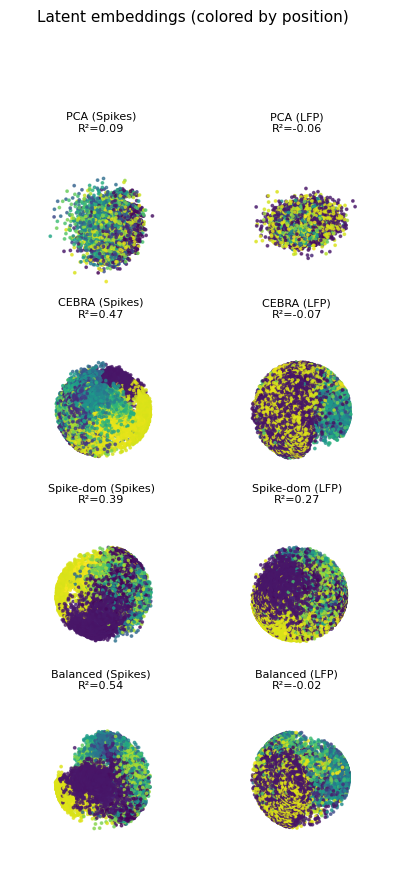

In [12]:
n_lat  = len(LAT_ORDER)
fig, axes = plt.subplots(n_lat, 2, figsize=(5, n_lat * 2.4),
                         subplot_kw={"projection": "3d"},
                         gridspec_kw={"wspace": 0.02, "hspace": 0.02})

for r, name in enumerate(LAT_ORDER):
    for c, (Z_, r2_val, label) in enumerate([
        (LATENT_EMBEDS[name]["spikes"], DECODE[name]["r2_spk"], "Spikes"),
        (LATENT_EMBEDS[name]["lfp"],   DECODE[name]["r2_lfp"], "LFP"),
    ]):
        ax = axes[r, c]
        X, Y, Z3 = reduce_to_3d(Z_)
        ax.scatter(X, Y, Z3, c=position_roi, cmap="viridis", s=3, alpha=0.7)
        ax.set_title(f"{name} ({label})\nR²={r2_val:.2f}", fontsize=8, pad=2)
        ax.view_init(25, 35)
        ax.set_axis_off()
        ax.set_box_aspect([1, 1, 1])
        for pane in (ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane):
            pane.fill = False
        ax.grid(False)

fig.suptitle("Latent embeddings (colored by position)", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

---
## Section 3 — Trajectory Plots

Decoded position (test set, spikes + LFP concat) per latent condition.

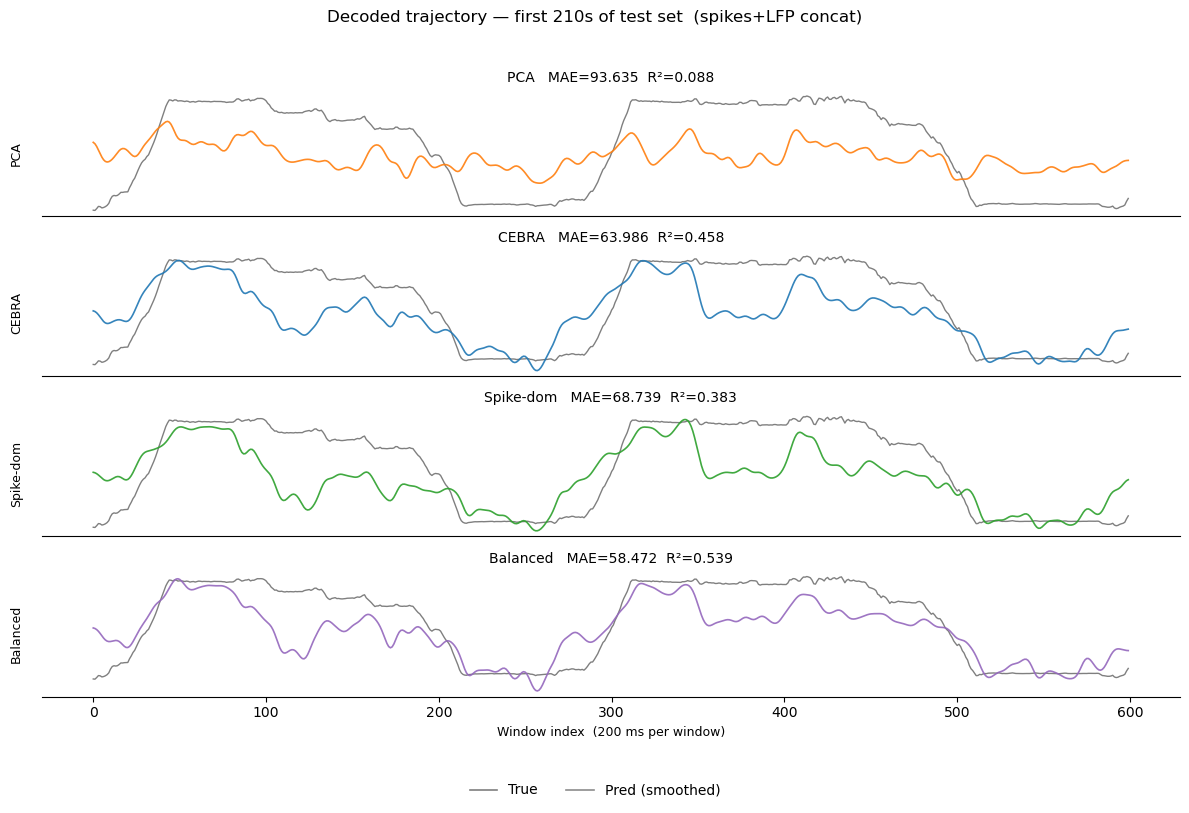

In [13]:
_colors = {"PCA": "tab:orange", "CEBRA": "tab:blue",
           "Spike-dom": "tab:green", "Balanced": "tab:purple"}

# show ~60 s of test data; gaussian-smooth predictions for display only
WIN_SIZE   = 10          # must match window_ridge_decode default
SHOW_SEC   = 210          # seconds to display
Nshow      = int(SHOW_SEC * fs_common / WIN_SIZE)
sigma_disp = 3           # smoothing in windows (~0.6 s at 5 Hz)

n_lat = len(LAT_ORDER)
nw    = len(position_roi) // WIN_SIZE
y_win = position_roi[:nw * WIN_SIZE].reshape(nw, WIN_SIZE).mean(axis=1)

fig, axes = plt.subplots(n_lat, 1, figsize=(12, n_lat * 2), sharex=True)
if n_lat == 1: axes = [axes]

from scipy.ndimage import gaussian_filter1d

for i, (ax, name) in enumerate(zip(axes, LAT_ORDER)):
    d    = DECODE[name]
    ytru = y_win[d["ntr"]:]
    yhat = d["y_pred"]
    n    = min(Nshow, len(ytru), len(yhat))

    yhat_smooth = gaussian_filter1d(yhat[:n].astype(float), sigma=sigma_disp)

    ax.plot(ytru[:n],    color="black",                  lw=1.0, alpha=0.5, label="True")
    ax.plot(yhat_smooth, color=_colors.get(name, "gray"), lw=1.2, alpha=0.9, label="Pred (smoothed)")
    ax.set_title(f"{name}   MAE={d['mae_cat']:.3f}  R²={d['r2_cat']:.3f}", fontsize=10)

    for spine in ["top", "left", "right"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(left=False, labelleft=False,
                   bottom=(i == n_lat - 1), labelbottom=(i == n_lat - 1))
    if i == n_lat - 1:
        ax.set_xlabel(f"Window index  ({WIN_SIZE * bin_size_ms:.0f} ms per window)", fontsize=9)
    ax.set_ylabel(name, rotation=90, fontsize=9, labelpad=18, va="center")

handles = [plt.Line2D([0],[0], color="black", lw=1.2, alpha=0.5, label="True"),
           plt.Line2D([0],[0], color="gray",  lw=1.2, alpha=0.9, label="Pred (smoothed)")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f"Decoded trajectory — first {SHOW_SEC}s of test set  (spikes+LFP concat)", fontsize=12)
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

---
## Section 4 — Unit Embedding Grid Search

Trains `len(LAT_ORDER) × len(UNIT_CFGS)` unit embeddings — edit **UNIT_CFGS** in the Configure cell.

| Unit config | λ\_coact | λ\_ctx |
|-------------|----------|--------|
| Coact-only  | 1.0      | 0.0    |
| Balanced    | 1.0      | 1.0    |
| Ctx-only    | 0.0      | 1.0    |

Split-half pairs trained with `EPOCHS // 2` for stability metric.

Place cells (SI permutation p<0.05): 42/83  (50.6%)
SI range: [0.00, 3.60] bits/spike


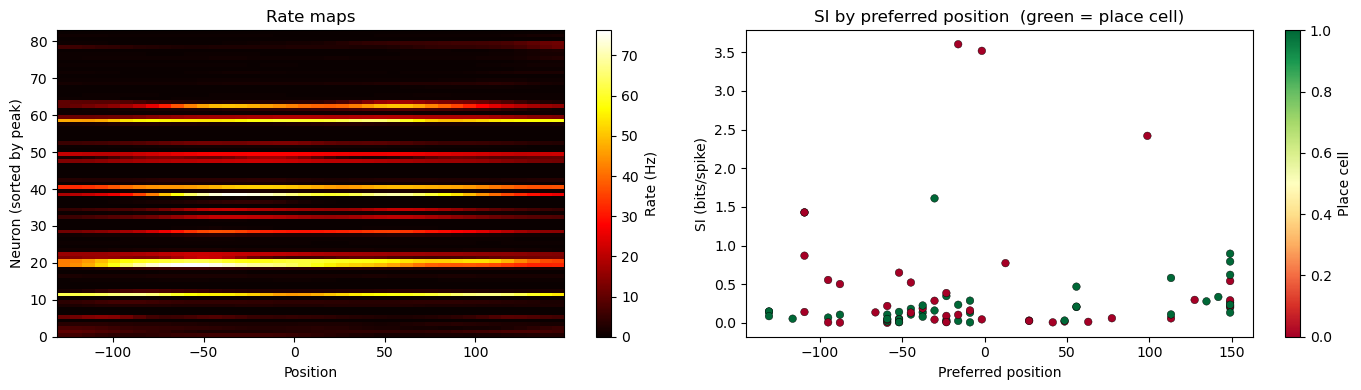

In [14]:
ratemaps, bin_centers = compute_ratemaps(spike_count_roi, position_roi, n_bins=40, sigma=2.0)
is_place_cell, si_obs = identify_place_cells(
    spike_count_roi, position_roi, n_bins=40, sigma=2.0, n_perms=500, p_thresh=0.05, seed=42,
)
n_pc = is_place_cell.sum()
print(f"Place cells (SI permutation p<0.05): {n_pc}/{N}  ({100*n_pc/N:.1f}%)")
print(f"SI range: [{si_obs.min():.2f}, {si_obs.max():.2f}] bits/spike")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
im = axes[0].imshow(ratemaps[np.argsort(ratemaps.argmax(axis=1))],
                    aspect="auto", origin="lower",
                    extent=[bin_centers[0], bin_centers[-1], 0, N], cmap="hot")
axes[0].set(xlabel="Position", ylabel="Neuron (sorted by peak)", title="Rate maps")
plt.colorbar(im, ax=axes[0], label="Rate (Hz)")

sc = axes[1].scatter(bin_centers[ratemaps.argmax(axis=1)], si_obs,
                     c=is_place_cell.astype(float), cmap="RdYlGn", s=30, edgecolors="k", lw=0.3)
axes[1].set(xlabel="Preferred position", ylabel="SI (bits/spike)",
            title="SI by preferred position  (green = place cell)")
plt.colorbar(sc, ax=axes[1], label="Place cell")
plt.tight_layout(); plt.show()

In [15]:
_base_unit = dict(lr=1e-3, d_u=D_U, m_units=32, temperature=0.1, win_len=5)
T_half = T // 2

UNIT_EMBEDDINGS = {}   # "lat | unit" → E [N, d_u]
SPLIT_E1        = {}   # split-half first half
SPLIT_E2        = {}   # split-half second half

for lat in LAT_ORDER:
    z_spk = LATENT_EMBEDS[lat]["spikes"]
    z_lfp = LATENT_EMBEDS[lat]["lfp"]

    for unit_name, unit_kw in UNIT_CFGS:
        key = f"{lat} | {unit_name}"
        print(f"\n{key}")

        cfg   = UnitTrainingConfig(epochs=EPOCHS, **_base_unit, **unit_kw)
        enc   = train_unit(None, spike_count_roi, sampling, cfg, z_spikes=z_spk, z_lfp=z_lfp)
        UNIT_EMBEDDINGS[key] = enc.embeddings().numpy()

        cfg_h = UnitTrainingConfig(epochs=EPOCHS // 2, **_base_unit, **unit_kw)
        SPLIT_E1[key] = train_unit(
            None, spike_count_roi[:T_half], sampling, cfg_h,
            z_spikes=z_spk[:T_half], z_lfp=z_lfp[:T_half],
        ).embeddings().numpy()
        SPLIT_E2[key] = train_unit(
            None, spike_count_roi[T_half:], sampling, cfg_h,
            z_spikes=z_spk[T_half:], z_lfp=z_lfp[T_half:],
        ).embeddings().numpy()

n_tot = len(LAT_ORDER) * len(UNIT_CFGS)
print(f"\nGrid search complete: {n_tot} full + {n_tot*2} split-half encoders.")


PCA | Coact-only


Stage 2: Unit Encoder: 100%|██████████| 50/50 [00:06<00:00,  7.36it/s, loss=-0.5576, lr=0.00e+00]



PCA | Balanced


Stage 2: Unit Encoder: 100%|██████████| 50/50 [00:06<00:00,  7.30it/s, loss=-1.7482, lr=0.00e+00]



PCA | Ctx-only


Stage 2: Unit Encoder: 100%|██████████| 50/50 [00:06<00:00,  7.55it/s, loss=-2.8998, lr=0.00e+00]


... (15 outputs left out)

Stage 2: Unit Encoder: 100%|██████████| 50/50 [00:08<00:00,  6.03it/s, loss=-2.0308, lr=0.00e+00]



Balanced | Ctx-only


Stage 2: Unit Encoder: 100%|██████████| 50/50 [00:06<00:00,  7.71it/s, loss=-3.3166, lr=0.00e+00]


Grid search complete: 12 full + 24 split-half encoders.


---
## Section 5 — Eval Unit

Metrics (all ↑ = better):
1. **ratemap\_correlation** — cosine similarity in E vs cosine similarity in rate maps
2. **si\_gradient\_correlation** — |SI\_i − SI\_j| vs embedding cosine distance
3. **split\_half\_stability** — Procrustes-aligned cosine similarity across temporal halves

In [16]:
EVAL_RESULTS = {}

for key in UNIT_EMBEDDINGS:
    E = UNIT_EMBEDDINGS[key]
    rho, _ = ratemap_correlation(E, ratemaps)
    sig, _ = si_gradient_correlation(E, si_obs)
    stab   = split_half_stability(SPLIT_E1[key], SPLIT_E2[key])
    EVAL_RESULTS[key] = (rho, sig, stab)

print(f"{'Config':<30}  {'ρ_ratemap':>10} {'ρ_SI_grad':>10} {'stability':>10}")
print("-" * 64)
for key, (rho, sig, stab) in EVAL_RESULTS.items():
    print(f"{key:<30}  {rho:>+10.3f} {sig:>+10.3f} {stab:>10.3f}")

Config                           ρ_ratemap  ρ_SI_grad  stability
----------------------------------------------------------------
PCA | Coact-only                    +0.488     +0.416      0.571
PCA | Balanced                      +0.530     +0.456      0.593
PCA | Ctx-only                      +0.530     +0.460      0.622
CEBRA | Coact-only                  +0.538     +0.425      0.593
CEBRA | Balanced                    +0.621     +0.470      0.594
CEBRA | Ctx-only                    +0.666     +0.492      0.652
Spike-dom | Coact-only              +0.540     +0.427      0.546
Spike-dom | Balanced                +0.617     +0.471      0.610
Spike-dom | Ctx-only                +0.681     +0.495      0.649
Balanced | Coact-only               +0.543     +0.417      0.561
Balanced | Balanced                 +0.625     +0.468      0.614
Balanced | Ctx-only                 +0.661     +0.475      0.645


/tmp/ipykernel_3101303/3310997157.py:23: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


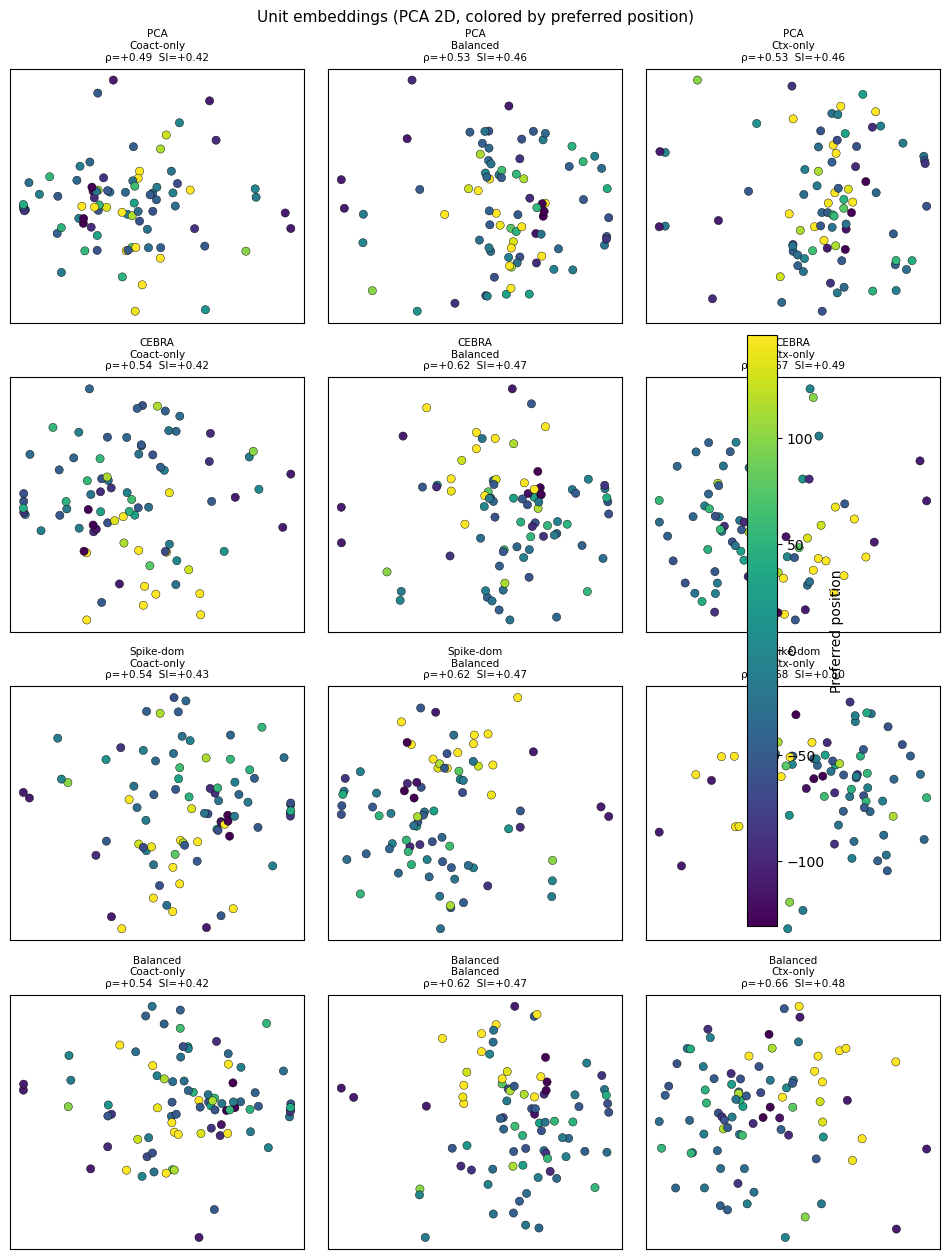

In [17]:
peak_pos = bin_centers[ratemaps.argmax(axis=1)]   # [N] preferred position

n_lat  = len(LAT_ORDER)
n_unit = len(UNIT_CFGS)
fig, axes = plt.subplots(n_lat, n_unit, figsize=(n_unit * 3.2, n_lat * 3.2))
if n_lat  == 1: axes = axes[np.newaxis, :]
if n_unit == 1: axes = axes[:, np.newaxis]

last_sc = None
for r, lat in enumerate(LAT_ORDER):
    for c, (unit_name, _) in enumerate(UNIT_CFGS):
        key = f"{lat} | {unit_name}"
        ax  = axes[r, c]
        E2  = PCA(n_components=2).fit_transform(UNIT_EMBEDDINGS[key])
        rho, sig, _ = EVAL_RESULTS[key]
        last_sc = ax.scatter(E2[:, 0], E2[:, 1], c=peak_pos, cmap="viridis",
                             s=35, edgecolors="k", lw=0.3)
        ax.set_title(f"{lat}\n{unit_name}\nρ={rho:+.2f}  SI={sig:+.2f}", fontsize=7.5)
        ax.set_xticks([]); ax.set_yticks([])

plt.colorbar(last_sc, ax=axes.ravel().tolist(), label="Preferred position", shrink=0.6)
fig.suptitle("Unit embeddings (PCA 2D, colored by preferred position)", fontsize=11)
plt.tight_layout()
plt.show()

In [18]:
keys  = list(EVAL_RESULTS)
vals  = np.array([EVAL_RESULTS[k] for k in keys])
ranks = np.argsort(np.argsort(-vals, axis=0), axis=0) + 1
order = np.argsort(ranks.mean(axis=1))

W = 74
print("=" * W)
print("UNIT EMBEDDING RANKING  (all metrics: higher = better)")
print("=" * W)
print(f"{'Rank':<5} {'Config':<30}  {'ρ_ratemap':>10} {'ρ_SI_grad':>10} {'stability':>10}")
print("-" * W)
for rank_i, idx in enumerate(order, 1):
    k = keys[idx]
    rho, sig, stab = EVAL_RESULTS[k]
    print(f"  {rank_i:<3} {k:<30}  {rho:>+10.3f} {sig:>+10.3f} {stab:>10.3f}")
print("=" * W)

UNIT EMBEDDING RANKING  (all metrics: higher = better)
Rank  Config                           ρ_ratemap  ρ_SI_grad  stability
--------------------------------------------------------------------------
  1   Spike-dom | Ctx-only                +0.681     +0.495      0.649
  2   CEBRA | Ctx-only                    +0.666     +0.492      0.652
  3   Balanced | Ctx-only                 +0.661     +0.475      0.645
  4   Balanced | Balanced                 +0.625     +0.468      0.614
  5   Spike-dom | Balanced                +0.617     +0.471      0.610
  6   CEBRA | Balanced                    +0.621     +0.470      0.594
  7   PCA | Ctx-only                      +0.530     +0.460      0.622
  8   CEBRA | Coact-only                  +0.538     +0.425      0.593
  9   PCA | Balanced                      +0.530     +0.456      0.593
  10  Spike-dom | Coact-only              +0.540     +0.427      0.546
  11  Balanced | Coact-only               +0.543     +0.417      0.561
  12  PCA | Coact-